# StyTr² Implementation — COMP9444 Project 007: Image Style Transfer

This notebook re-implements **StyTr²: Image Style Transfer with Transformers** (Deng et al., CVPR 2022) in PyTorch and trains it on the project's `datasets/` folder (COCO 2014 content images + WikiArt style images from 7 artist/style categories).

本 notebook 用 PyTorch 复现 **StyTr²**（Deng et al., CVPR 2022），并在项目的 `datasets/` 目录上训练（内容图来自 COCO 2014，风格图来自 WikiArt 的 7 个画家/风格类别）。

**Pipeline / 流程**

```
content ─► Patch Embedding (8×8) ─► + CAPE ─► Transformer Encoder (content) ─┐
                                                                             ├─► Transformer Decoder ─► CNN Decoder (×8 upsample) ─► stylised image
style   ─► Patch Embedding (8×8) ──────────► Transformer Encoder (style)  ───┘   (Q = content, K/V = style)

Loss (VGG-19, frozen): λc·Lc + λs·Ls + λid1·Lid1 + λid2·Lid2
```

**Role in this project / 在项目中的作用**: control group (baseline) for comparison with our own model. The implementation is based on StyTr² (Deng et al., CVPR 2022) and its official repository [diyiiyiii/StyTR-2](https://github.com/diyiiyiii/StyTR-2), re-written by our team.

本 notebook 作为对照组，用于和我们自己的模型比较；实现基于 StyTr² 论文及其官方代码，由小组重新编写。


## 1. Environment Setup / 环境配置

> **RTX 50-series GPUs (e.g. RTX 5060 Ti, Blackwell, `sm_120`) need a PyTorch build with CUDA ≥ 12.8**, e.g.
> `pip install torch torchvision --index-url https://download.pytorch.org/whl/cu128`.
> The cell below warns if the installed PyTorch does not support your GPU.
>
> RTX 50 系显卡需要 CUDA 12.8 以上编译的 PyTorch，下面的单元会检查。

In [1]:
import os
import sys
import math
import time
import json
import random
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision
from torchvision import transforms
from torchvision.utils import make_grid, save_image

try:
    from tqdm.auto import tqdm
except ImportError:          # tqdm 不是必须的
    def tqdm(x, **kwargs):
        return x

print("Python     :", sys.version.split()[0])
print("PyTorch    :", torch.__version__)
print("torchvision:", torchvision.__version__)

Python     : 3.13.14
PyTorch    : 2.8.0+cu129
torchvision: 0.23.0+cu129


C:\Users\Administrator\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
    major, minor = torch.cuda.get_device_capability()
    print("GPU        :", torch.cuda.get_device_name(0))
    print("Capability : sm_%d%d" % (major, minor))
    print("VRAM       : %.1f GB" % (torch.cuda.get_device_properties(0).total_memory / 1024**3))
    # 检查 PyTorch 是否编译了当前显卡的架构（RTX 50 系 = sm_120）
    if f"sm_{major}{minor}" not in torch.cuda.get_arch_list():
        print("WARNING: this PyTorch build does not list sm_%d%d. "
              "Install a build with CUDA >= 12.8 for RTX 50-series GPUs." % (major, minor))
    torch.backends.cudnn.benchmark = True
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True
elif torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")

print("Selected device:", DEVICE)

GPU        : NVIDIA GeForce RTX 5060 Ti
Capability : sm_120
VRAM       : 15.9 GB
Selected device: cuda


## 2. Experiment Configuration / 实验配置

All hyper-parameters are kept in one dictionary so they can be reported in the summary report.

所有超参数集中在一个字典里，方便在报告的 Experimental Setup 中引用。

- `pos_encoding`: `"cape"` = StyTr² (group C), `"sine"` = sinusoidal PE (ablation group D), `"none"` = no PE.
- `quick_test = True` runs a few hundred iterations on a small subset with a fixed, low learning rate (1e-4) to check that the whole notebook works. It does not indicate final quality.
- The paper trains 160k iterations on 4 GPUs (~1 day). On a single GPU we default to 40k iterations; increase `max_iters` if time allows.

- `quick_test = True`：用固定的低学习率（1e-4）只跑几百步，检查整个 notebook 能否跑通，不代表最终效果。
- 论文在 4 张 GPU 上训练 16 万步；单卡默认 4 万步，时间允许可以调大 `max_iters`。

In [130]:
PROJECT_ROOT = Path.cwd()          # 把本 notebook 放在 Project 目录下（与 datasets/ 同级）

CONFIG = {
    # ---- 路径 ----
    "data_root": PROJECT_ROOT / "datasets",
    "cache_root": PROJECT_ROOT / "datasets_cache_512",
    "output_dir": PROJECT_ROOT / "outputs" / "stytr2_cape",

    # ---- 数据 ----
    "cache_short_side": 512,       # 预处理：短边缩放到 512（对应论文先 resize 到 512）
    "image_size": 256,             # 训练随机裁剪尺寸（论文：256×256）
    "val_content_ratio": 0.05,     # 从 content_train 中划出 5% 作为验证集
    "val_style_per_class": 14,     # 每个风格类别划出 14 张作为验证集（140 → 126 / 14）

    # ---- 模型（与论文一致）----
    "patch_size": 8,
    "d_model": 512,
    "nhead": 8,
    "num_enc_layers": 3,
    "num_dec_layers": 3,
    "dim_feedforward": 2048,
    "dropout": 0.1,
    "cape_pool_size": 18,          # CAPE 的 n×n，论文 n = 18
    "pos_encoding": "cape",        # "cape" | "sine" | "none"

    # ---- 训练 ----
    "batch_size": 8,               # 论文：8；显存不足时改成 4
    "lr": 5e-4,                    # 论文：5e-4 + warm-up
    "warmup_iters": 10_000,
    "lr_decay": 1e-5,
    "fixed_lr": None,              # 设为数值时不用 warm-up/衰减，固定学习率（quick test 用）
    "grad_clip": 1.0,              # 梯度裁剪阈值（None 表示不裁剪）
    "collapse_std": 0.02,          # 输出图像素标准差低于该值时警告（可能塌缩成纯色图）
    "max_iters": 40_000,
    "lambda_c": 10.0,
    "lambda_s": 7.0,
    "lambda_id1": 50.0,
    "lambda_id2": 1.0,
    "use_amp": True,               # 混合精度（支持 bf16 的显卡优先用 bf16）
    "num_workers": 0 if os.name == "nt" else min(4, os.cpu_count() or 1),   # Windows 的 notebook 里多进程加载会报错，设为 0
    "resume": True,                # 若存在 checkpoint 则继续训练

    # ---- 日志 ----
    "log_every": 100,
    "val_every": 1_000,
    "sample_every": 2_000,
    "save_every": 2_000,

    # ---- 评估 ----
    "eval_num_content": None,      # 测试：None = 全部 400 张内容图；每个风格类别各生成一遍（7 × 400 = 2800 张）

    "seed": 42,
    "quick_test": False,
}

if CONFIG["quick_test"]:
    CONFIG.update({
        "max_iters": 300, "fixed_lr": 1e-4, "batch_size": 8,
        "log_every": 20, "val_every": 100, "sample_every": 100, "save_every": 100,
        "eval_num_content": 4,
        "output_dir": PROJECT_ROOT / "outputs" / "stytr2_quick_test",
    })

# 注意：不要按总步数压缩 warm-up。之前 quick test 把 warm-up 压到 75 步，学习率升得太快，导致模型塌缩成纯色输出

OUTPUT_DIR = Path(CONFIG["output_dir"])
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
(OUTPUT_DIR / "samples").mkdir(exist_ok=True)

with open(OUTPUT_DIR / "config.json", "w", encoding="utf-8") as f:
    json.dump({k: str(v) for k, v in CONFIG.items()}, f, indent=2)

pd.Series({k: str(v) for k, v in CONFIG.items()}, name="value").to_frame()

,value
data_root,d:\9444\Project\datasets
cache_root,d:\9444\Project\datasets_cache_512
output_dir,d:\9444\Project\outputs\stytr2_cape
cache_short_side,512
image_size,256
val_content_ratio,0.05
val_style_per_class,14
patch_size,8
d_model,512
nhead,8


## 3. Reproducibility / 实验可复现性

In [131]:
def seed_everything(seed: int) -> None:
    # 固定 Python、NumPy 和 PyTorch 的随机数
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


seed_everything(CONFIG["seed"])
print("Random seed:", CONFIG["seed"])

Random seed: 42


## 4. Dataset and Splits / 数据集与划分

The `datasets/` folder is already split into train and test:

| Folder | Content |
|---|---|
| `content_train/` | 7,500 COCO 2014 images |
| `content_test/` | 400 COCO 2014 images |
| `style_train/<category>/` | 7 categories × 140 WikiArt paintings |
| `style_test/<category>/` | 7 categories × 40 WikiArt paintings |

We further hold out a **validation set** from the training folders (5% of content images and 14 paintings per style category), used for checkpoint selection. The test set is only used for the final evaluation.

在训练集中再划出**验证集**（5% 内容图，每个风格类 14 张），用于选择 checkpoint；测试集只用于最终评估。风格图按类别分层划分，保证每个类别都在验证集中出现。

In [132]:
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}


def list_images(root: Path) -> list:
    # 递归扫描文件夹中的所有图片
    if not root.exists():
        return []
    return sorted(p for p in root.rglob("*") if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS)


DATA_ROOT = Path(CONFIG["data_root"])
assert DATA_ROOT.exists(), f"Dataset folder not found: {DATA_ROOT}"

content_train_all = list_images(DATA_ROOT / "content_train")
content_test = list_images(DATA_ROOT / "content_test")
style_train_all = list_images(DATA_ROOT / "style_train")
style_test = list_images(DATA_ROOT / "style_test")

STYLE_CLASSES = sorted(p.name for p in (DATA_ROOT / "style_train").iterdir() if p.is_dir())
print("Style categories:", STYLE_CLASSES)

Style categories: ['edvard_expressionism', 'hokusai_ukiyoe', 'monet_impressionism', 'picasso_cubism', 'picasso_expressionism', 'renoir_impressionism', 'vangogh_realism']


In [133]:
rng = random.Random(CONFIG["seed"])

# ---- 内容图：随机划出验证集 ----
shuffled = content_train_all.copy()
rng.shuffle(shuffled)
n_val = max(1, int(len(shuffled) * CONFIG["val_content_ratio"]))
content_val = sorted(shuffled[:n_val])
content_train = sorted(shuffled[n_val:])

# ---- 风格图：按类别分层划分 ----
style_train, style_val = [], []
for cls in STYLE_CLASSES:
    imgs = sorted(p for p in style_train_all if p.parent.name == cls)
    rng.shuffle(imgs)
    k = min(CONFIG["val_style_per_class"], max(1, len(imgs) // 10))
    style_val += imgs[:k]
    style_train += imgs[k:]
style_train, style_val = sorted(style_train), sorted(style_val)

# ---- 检查数据泄漏 ----
for a, b in [(content_train, content_val), (content_train, content_test), (content_val, content_test),
             (style_train, style_val), (style_train, style_test), (style_val, style_test)]:
    assert set(a).isdisjoint(b)

if CONFIG["quick_test"]:           # 快速测试只用一小部分数据
    content_train = content_train[:200]
    style_train = style_train[::max(1, len(style_train) // 70)]   # 每类都保留一些

split_table = pd.DataFrame({
    "train": [len(content_train), len(style_train)],
    "validation": [len(content_val), len(style_val)],
    "test": [len(content_test), len(style_test)],
}, index=["content (COCO)", "style (WikiArt)"])
display(split_table)
print("No overlap between splits.")

,train,validation,test
content (COCO),7125,375,400
style (WikiArt),882,98,280


No overlap between splits.


,train,validation,test
edvard_expressionism,126,14,40
hokusai_ukiyoe,126,14,40
monet_impressionism,126,14,40
picasso_cubism,126,14,40
picasso_expressionism,126,14,40
renoir_impressionism,126,14,40
vangogh_realism,126,14,40


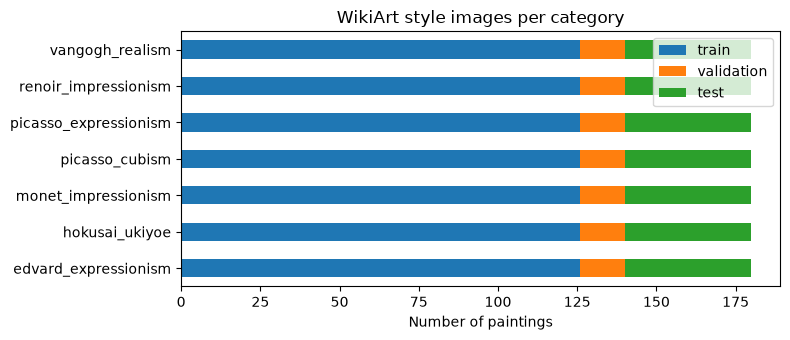

In [134]:
# 每个风格类别在各划分中的数量
counts = pd.DataFrame({
    split: pd.Series([p.parent.name for p in paths]).value_counts()
    for split, paths in [("train", style_train), ("validation", style_val), ("test", style_test)]
}).reindex(STYLE_CLASSES).fillna(0).astype(int)
display(counts)

ax = counts.plot(kind="barh", stacked=True, figsize=(8, 3.5))
ax.set_xlabel("Number of paintings")
ax.set_title("WikiArt style images per category")
plt.tight_layout()
plt.show()

## 5. Preprocessing Cache / 预处理缓存

WikiArt paintings are large (often > 1,400 px on the short side), so decoding them every iteration would make data loading the bottleneck. We resize every image once so that its **short side is 512 px** (keeping the aspect ratio) and save it to `datasets_cache_512/`. The paper also resizes to 512 before random 256×256 crops, but distorts the aspect ratio; we keep it.

WikiArt 原图很大，每步都解码会拖慢训练。这里一次性把所有图片短边缩放到 512（保持长宽比）并缓存。损坏的图片会被记录并跳过。只需运行一次。

In [135]:
CACHE_ROOT = Path(CONFIG["cache_root"])


def cache_path(src: Path) -> Path:
    return CACHE_ROOT / src.relative_to(DATA_ROOT).with_suffix(".jpg")


def resize_short_side(src: Path, short_side: int):
    dst = cache_path(src)
    if dst.exists():
        return None
    try:
        with Image.open(src) as img:
            img.draft("RGB", (short_side, short_side))   # JPEG 快速降采样解码
            img = img.convert("RGB")
            w, h = img.size
            scale = short_side / min(w, h)
            img = img.resize((max(1, round(w * scale)), max(1, round(h * scale))), Image.BICUBIC)
            dst.parent.mkdir(parents=True, exist_ok=True)
            img.save(dst, quality=95)
        return None
    except Exception as e:
        return (str(src), str(e))


all_sources = content_train_all + content_test + style_train_all + style_test
with ThreadPoolExecutor(max_workers=8) as pool:
    results = list(tqdm(pool.map(lambda p: resize_short_side(p, CONFIG["cache_short_side"]), all_sources),
                        total=len(all_sources), desc="Caching"))

corrupt = [r for r in results if r is not None]
print("Cached images :", len(all_sources) - len(corrupt))
print("Corrupt images:", len(corrupt))
for r in corrupt[:10]:
    print("  ", r)

# 后面全部使用缓存路径，并去掉损坏的图片
bad = {Path(r[0]) for r in corrupt}
to_cache = lambda paths: [cache_path(p) for p in paths if p not in bad]
c_train, c_val, c_test = map(to_cache, (content_train, content_val, content_test))
s_train, s_val, s_test = map(to_cache, (style_train, style_val, style_test))

Caching: 100%|██████████| 9160/9160 [00:00<00:00, 10827.00it/s]


Cached images : 9160
Corrupt images: 0


## 6. Dataset and DataLoader / 数据加载

- **Training**: random 256×256 crop (as in the paper). No colour augmentation, because colour is part of the style.
- **Validation / test**: resize the short side to 256 and centre-crop 256×256, so results are deterministic.
- Images are kept in [0, 1]; ImageNet normalisation is applied only inside the VGG loss network.

- 训练：随机裁剪 256×256；不做颜色增强，因为颜色本身属于风格。
- 验证/测试：短边缩放到 256 后中心裁剪，保证结果确定。

In [136]:
IMG = CONFIG["image_size"]

train_tf = transforms.Compose([
    transforms.Resize(CONFIG["cache_short_side"]),
    transforms.RandomCrop(IMG),
    transforms.ToTensor(),
])
eval_tf = transforms.Compose([
    transforms.Resize(IMG),
    transforms.CenterCrop(IMG),
    transforms.ToTensor(),
])


class ImageDataset(Dataset):
    def __init__(self, paths, transform):
        self.paths = list(paths)
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        with Image.open(self.paths[idx]) as img:
            return self.transform(img.convert("RGB"))


def make_loader(paths, shuffle=True):
    return DataLoader(
        ImageDataset(paths, train_tf), batch_size=CONFIG["batch_size"], shuffle=shuffle,
        drop_last=True, num_workers=CONFIG["num_workers"], pin_memory=(DEVICE.type == "cuda"),
        persistent_workers=CONFIG["num_workers"] > 0,
    )


def infinite(loader):
    # 无限循环的迭代器：内容集和风格集大小不同，各自独立循环
    while True:
        for batch in loader:
            yield batch


content_loader = make_loader(c_train)
style_loader = make_loader(s_train)


def load_eval_batch(paths):
    return torch.stack([eval_tf(Image.open(p).convert("RGB")) for p in paths])


# 固定的验证对：每个 batch 的内容图和风格图一一配对
n_val_pairs = min(32, len(c_val), len(s_val))
val_rng = random.Random(CONFIG["seed"])
val_content = load_eval_batch(val_rng.sample(c_val, n_val_pairs))
val_style = load_eval_batch(val_rng.sample(s_val, n_val_pairs))
print("Train batches per epoch (content / style):", len(content_loader), "/", len(style_loader))
print("Validation pairs:", n_val_pairs)

Train batches per epoch (content / style): 890 / 110
Validation pairs: 32


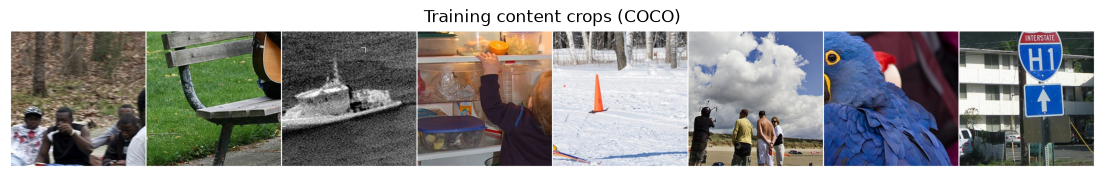

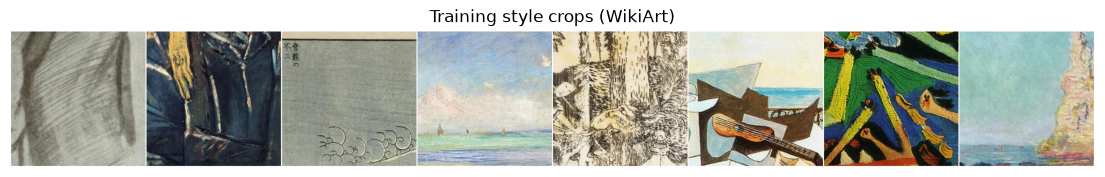

In [137]:
def show_tensor_grid(tensor, title=None, nrow=8, figsize=(14, 4)):
    grid = make_grid(tensor.clamp(0, 1).cpu(), nrow=nrow, padding=2, pad_value=1.0)
    plt.figure(figsize=figsize)
    plt.imshow(grid.permute(1, 2, 0).numpy())
    plt.axis("off")
    if title:
        plt.title(title)
    plt.show()


sample_c = next(iter(content_loader))
sample_s = next(iter(style_loader))
show_tensor_grid(sample_c, "Training content crops (COCO)")
show_tensor_grid(sample_s, "Training style crops (WikiArt)")

## 7. Model / 模型

### 7.1 Patch Embedding and Positional Encodings / 图像块嵌入与位置编码

**Patch embedding**: an 8×8 convolution with stride 8 turns an H×W image into an (H/8)×(W/8) grid of 512-d tokens.

**CAPE (content-aware positional encoding)**, paper Eq. (3): average-pool the content embedding to a fixed 18×18 grid, apply a learnable 1×1 convolution, then bilinearly interpolate back to (H/8)×(W/8). Because the encoding is defined on a fixed grid and then resized, the relative position of two patches does not change with image resolution (scale-invariant), and it depends on the image content.

**Sinusoidal PE** (ablation): the standard 2-D sine/cosine encoding (DETR style). It uses absolute patch indices, so a 512×512 input produces encodings never seen during 256×256 training — the paper shows this causes vertical-track artefacts.

- 图像块嵌入：8×8、步长 8 的卷积，把图像变成 (H/8)×(W/8) 个 512 维 token。
- CAPE：先把内容嵌入平均池化到固定的 18×18，经过 1×1 卷积学习位置编码，再插值回 (H/8)×(W/8)。因此位置编码与分辨率无关，并且依赖图像内容。
- 正弦编码（消融实验用）：使用绝对坐标，输入分辨率变化时编码会大幅变化。

In [138]:
class PatchEmbed(nn.Module):
    def __init__(self, patch_size=8, in_chans=3, embed_dim=512):
        super().__init__()
        self.proj = nn.Conv2d(in_chans, embed_dim, kernel_size=patch_size, stride=patch_size)

    def forward(self, x):                      # B,3,H,W -> B,C,H/8,W/8
        return self.proj(x)


class CAPE(nn.Module):
    # 内容感知位置编码（论文 3.1 节，公式 3）
    def __init__(self, d_model=512, pool_size=18):
        super().__init__()
        self.pool = nn.AdaptiveAvgPool2d(pool_size)
        self.proj = nn.Conv2d(d_model, d_model, kernel_size=1)   # F_pos：可学习的 1×1 卷积

    def forward(self, x):                      # x: 内容嵌入 B,C,h,w
        pos = self.proj(self.pool(x))          # B,C,18,18
        return F.interpolate(pos, size=x.shape[-2:], mode="bilinear", align_corners=False)


def sine_positional_encoding(x, temperature=10000):
    # 二维正弦位置编码（DETR 风格），使用绝对坐标，作为消融对比
    b, c, h, w = x.shape
    npf = c // 2
    y_embed = torch.arange(1, h + 1, device=x.device, dtype=torch.float32)[:, None].expand(h, w)
    x_embed = torch.arange(1, w + 1, device=x.device, dtype=torch.float32)[None, :].expand(h, w)
    dim_t = torch.arange(npf, device=x.device, dtype=torch.float32)
    dim_t = temperature ** (2 * (dim_t // 2) / npf)
    pos_x = x_embed[..., None] / dim_t
    pos_y = y_embed[..., None] / dim_t
    pos_x = torch.stack((pos_x[..., 0::2].sin(), pos_x[..., 1::2].cos()), dim=3).flatten(2)
    pos_y = torch.stack((pos_y[..., 0::2].sin(), pos_y[..., 1::2].cos()), dim=3).flatten(2)
    pos = torch.cat((pos_y, pos_x), dim=2).permute(2, 0, 1)   # C,h,w
    return pos.unsqueeze(0).expand(b, -1, -1, -1).to(x.dtype)

### 7.2 Transformer Encoders and Decoder / Transformer 编码器与解码器

DETR-style, post-norm layers:

- **Encoder layer**: multi-head self-attention + FFN. The positional encoding is added to the queries and keys (not the values). The content encoder uses CAPE; the style encoder uses **no** positional encoding, because the spatial layout of the style image should not be kept.
- **Decoder layer** (paper Eq. 8): two attention blocks, both with **Q from the content sequence and K, V from the style sequence**, followed by an FFN. All tokens are decoded at once (not auto-regressive).

- 编码器层：多头自注意力 + 前馈网络；位置编码加在 Q 和 K 上。内容编码器用 CAPE，风格编码器不用位置编码。
- 解码器层（公式 8）：两个注意力模块的 Q 都来自内容序列，K、V 来自风格序列，然后接前馈网络；一次性输出所有 token。

In [139]:
def with_pos(x, pos):
    return x if pos is None else x + pos


class EncoderLayer(nn.Module):
    def __init__(self, d_model, nhead, dim_ff, dropout):
        super().__init__()
        self.self_attn = nn.MultiheadAttention(d_model, nhead, dropout=dropout, batch_first=True)
        self.linear1 = nn.Linear(d_model, dim_ff)
        self.linear2 = nn.Linear(dim_ff, d_model)
        self.norm1, self.norm2 = nn.LayerNorm(d_model), nn.LayerNorm(d_model)
        self.drop, self.drop1, self.drop2 = nn.Dropout(dropout), nn.Dropout(dropout), nn.Dropout(dropout)

    def forward(self, src, pos=None):
        q = k = with_pos(src, pos)
        src = self.norm1(src + self.drop1(self.self_attn(q, k, src, need_weights=False)[0]))
        ff = self.linear2(self.drop(F.relu(self.linear1(src))))
        return self.norm2(src + self.drop2(ff))


class DecoderLayer(nn.Module):
    def __init__(self, d_model, nhead, dim_ff, dropout):
        super().__init__()
        self.attn1 = nn.MultiheadAttention(d_model, nhead, dropout=dropout, batch_first=True)
        self.attn2 = nn.MultiheadAttention(d_model, nhead, dropout=dropout, batch_first=True)
        self.linear1 = nn.Linear(d_model, dim_ff)
        self.linear2 = nn.Linear(dim_ff, d_model)
        self.norm1, self.norm2, self.norm3 = nn.LayerNorm(d_model), nn.LayerNorm(d_model), nn.LayerNorm(d_model)
        self.drop = nn.Dropout(dropout)
        self.drop1, self.drop2, self.drop3 = nn.Dropout(dropout), nn.Dropout(dropout), nn.Dropout(dropout)

    def forward(self, tgt, memory, query_pos=None, pos=None):
        # tgt: 内容序列（Query）；memory: 风格序列（Key / Value）
        k = with_pos(memory, pos)
        tgt = self.norm1(tgt + self.drop1(self.attn1(with_pos(tgt, query_pos), k, memory, need_weights=False)[0]))
        tgt = self.norm2(tgt + self.drop2(self.attn2(with_pos(tgt, query_pos), k, memory, need_weights=False)[0]))
        ff = self.linear2(self.drop(F.relu(self.linear1(tgt))))
        return self.norm3(tgt + self.drop3(ff))


class StyleTransformer(nn.Module):
    def __init__(self, d_model=512, nhead=8, n_enc=3, n_dec=3, dim_ff=2048, dropout=0.1):
        super().__init__()
        self.encoder_c = nn.ModuleList([EncoderLayer(d_model, nhead, dim_ff, dropout) for _ in range(n_enc)])
        self.encoder_s = nn.ModuleList([EncoderLayer(d_model, nhead, dim_ff, dropout) for _ in range(n_enc)])
        self.decoder = nn.ModuleList([DecoderLayer(d_model, nhead, dim_ff, dropout) for _ in range(n_dec)])
        self.decoder_norm = nn.LayerNorm(d_model)
        for p in self.parameters():
            if p.dim() > 1:
                nn.init.xavier_uniform_(p)

    def forward(self, style, content, pos_c=None):
        # 输入均为 B,C,h,w；输出 B,C,h,w（h,w 与内容一致，支持非正方形）
        b, c, h, w = content.shape
        flat = lambda t: None if t is None else t.flatten(2).transpose(1, 2)   # B,C,h,w -> B,hw,C
        s, x, pc = flat(style), flat(content), flat(pos_c)
        for layer in self.encoder_s:
            s = layer(s, pos=None)             # 风格编码器：不加位置编码
        for layer in self.encoder_c:
            x = layer(x, pos=pc)               # 内容编码器：加 CAPE
        for layer in self.decoder:
            x = layer(x, s, query_pos=pc, pos=None)
        x = self.decoder_norm(x)
        return x.transpose(1, 2).reshape(b, c, h, w)

### 7.3 CNN Decoder / CNN 解码器

Instead of reshaping tokens directly into pixels, a CNN decoder progressively upsamples the transformer output by 2× three times (32→64→128→256 for a 256 input), using 3×3 conv + ReLU + nearest upsampling with reflection padding.

CNN 解码器把 Transformer 输出逐步上采样 3 次（共 8 倍），每层是 3×3 卷积 + ReLU + 最近邻上采样。

In [140]:
def conv_block(cin, cout, relu=True):
    layers = [nn.ReflectionPad2d(1), nn.Conv2d(cin, cout, 3)]
    if relu:
        layers.append(nn.ReLU(inplace=True))
    return layers


def build_cnn_decoder():
    up = lambda: nn.Upsample(scale_factor=2, mode="nearest")
    return nn.Sequential(
        *conv_block(512, 256), up(),
        *conv_block(256, 256), *conv_block(256, 256), *conv_block(256, 256),
        *conv_block(256, 128), up(),
        *conv_block(128, 128), *conv_block(128, 64), up(),
        *conv_block(64, 64), *conv_block(64, 3, relu=False),
    )

### 7.4 VGG-19 Loss Network and Loss Functions / VGG-19 损失网络与损失函数

A frozen ImageNet-pretrained VGG-19 provides features at relu1_1, relu2_1, relu3_1, relu4_1 and relu5_1.

| Loss | Definition | Paper |
|---|---|---|
| Content Lc | MSE between mean-variance-normalised features of output and content at relu4_1 and relu5_1 | Eq. 9 |
| Style Ls | MSE between channel-wise mean and std of output and style features, summed over the 5 layers | Eq. 10 |
| Identity Lid1 | Pixel MSE: StyTr²(c, c) should equal c and StyTr²(s, s) should equal s | Eq. 11 |
| Identity Lid2 | Same as Lid1 but on VGG features of all 5 layers | Eq. 11 |

Total: L = λc·Lc + λs·Ls + λid1·Lid1 + λid2·Lid2 (Eq. 12). Each term is logged separately so that their balance can be checked in the training curves.

VGG-19 冻结、只用于计算损失。四项损失分别记录，可在训练曲线中检查是否平衡。


In [141]:
class VGGFeatures(nn.Module):
    # 冻结的 VGG-19，输出 relu1_1 ~ relu5_1 五层特征
    LAYER_ENDS = [2, 7, 12, 21, 30]           # torchvision vgg19.features 中 relu1_1 … relu5_1 之后的位置

    def __init__(self):
        super().__init__()
        vgg = torchvision.models.vgg19(weights=torchvision.models.VGG19_Weights.IMAGENET1K_V1).features
        self.slices = nn.ModuleList()
        start = 0
        for end in self.LAYER_ENDS:
            self.slices.append(nn.Sequential(*[vgg[i] for i in range(start, end)]))
            start = end
        self.register_buffer("mean", torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))
        for p in self.parameters():
            p.requires_grad_(False)
        self.eval()

    def train(self, mode=True):               # 始终保持 eval 模式
        return super().train(False)

    def forward(self, x):                     # x 在 [0,1]
        x = (x - self.mean) / self.std
        feats = []
        for s in self.slices:
            x = s(x)
            feats.append(x)
        return feats


def calc_mean_std(feat, eps=1e-5):
    b, c = feat.shape[:2]
    var = feat.reshape(b, c, -1).var(dim=2) + eps
    return feat.reshape(b, c, -1).mean(dim=2).view(b, c, 1, 1), var.sqrt().view(b, c, 1, 1)


def mean_variance_norm(feat):
    mean, std = calc_mean_std(feat)
    return (feat - mean) / std


def content_loss(out_feats, content_feats):
    # 公式 9：relu4_1 和 relu5_1 的归一化特征
    return sum(F.mse_loss(mean_variance_norm(out_feats[i].float()), mean_variance_norm(content_feats[i].float()))
               for i in (-2, -1))


def style_loss(out_feats, style_feats):
    # 公式 10：五层特征的均值与标准差
    loss = 0.0
    for o, s in zip(out_feats, style_feats):
        om, os_ = calc_mean_std(o.float())
        sm, ss = calc_mean_std(s.float())
        loss = loss + F.mse_loss(om, sm) + F.mse_loss(os_, ss)
    return loss

### 7.5 Full StyTr² Model / 完整模型

In [142]:
class StyTr2(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        d = cfg["d_model"]
        self.patch = cfg["patch_size"]
        self.embed = PatchEmbed(cfg["patch_size"], 3, d)
        self.transformer = StyleTransformer(d, cfg["nhead"], cfg["num_enc_layers"], cfg["num_dec_layers"],
                                            cfg["dim_feedforward"], cfg["dropout"])
        self.decoder = build_cnn_decoder()
        self.pos_type = cfg["pos_encoding"]
        self.cape = CAPE(d, cfg["cape_pool_size"]) if self.pos_type == "cape" else None

    def positional_encoding(self, content_emb):
        if self.pos_type == "cape":
            return self.cape(content_emb)
        if self.pos_type == "sine":
            return sine_positional_encoding(content_emb)
        return None

    def forward(self, content, style):
        # 输入尺寸需为 8 的倍数；内容图与风格图尺寸可以不同
        c_emb, s_emb = self.embed(content), self.embed(style)
        pos_c = self.positional_encoding(c_emb)
        hs = self.transformer(s_emb, c_emb, pos_c)
        return self.decoder(hs)


def compute_losses(model, vgg, content, style, cfg):
    Ics = model(content, style)
    Icc = model(content, content)             # identity：内容图 + 内容图
    Iss = model(style, style)                 # identity：风格图 + 风格图

    f_c, f_s = vgg(content), vgg(style)
    f_cs, f_cc, f_ss = vgg(Ics), vgg(Icc), vgg(Iss)

    l_c = content_loss(f_cs, f_c)
    l_s = style_loss(f_cs, f_s)
    l_id1 = F.mse_loss(Icc.float(), content.float()) + F.mse_loss(Iss.float(), style.float())
    l_id2 = sum(F.mse_loss(a.float(), b.float()) + F.mse_loss(x.float(), y.float())
                for a, b, x, y in zip(f_cc, f_c, f_ss, f_s))
    total = (cfg["lambda_c"] * l_c + cfg["lambda_s"] * l_s
             + cfg["lambda_id1"] * l_id1 + cfg["lambda_id2"] * l_id2)
    return {"total": total, "content": l_c, "style": l_s, "id1": l_id1, "id2": l_id2}, Ics

In [143]:
model = StyTr2(CONFIG).to(DEVICE)
vgg = VGGFeatures().to(DEVICE)

count = lambda m: sum(p.numel() for p in m.parameters() if p.requires_grad)
param_table = pd.DataFrame({
    "parameters (M)": [count(model.embed) / 1e6,
                       (count(model.cape) if model.cape is not None else 0) / 1e6,
                       count(model.transformer) / 1e6, count(model.decoder) / 1e6, count(model) / 1e6],
}, index=["patch embedding", "CAPE", "transformer (2 enc + dec)", "CNN decoder", "total trainable"]).round(2)
display(param_table)

# 形状检查：正方形、非正方形输入，以及不同大小的风格图
with torch.no_grad():
    for cs, ss in [((256, 256), (256, 256)), ((256, 384), (256, 256)), ((512, 512), (256, 256))]:
        out = model(torch.rand(1, 3, *cs, device=DEVICE), torch.rand(1, 3, *ss, device=DEVICE))
        print(f"content {cs}, style {ss} -> output {tuple(out.shape[-2:])}")

,parameters (M)
patch embedding,0.10
CAPE,0.26
transformer (2 enc + dec),31.53
CNN decoder,3.51
total trainable,35.39


content (256, 256), style (256, 256) -> output (256, 256)
content (256, 384), style (256, 256) -> output (256, 384)
content (512, 512), style (256, 256) -> output (512, 512)


## 8. Training / 训练

- **Optimiser**: Adam. Only the patch embedding, CAPE, transformer and CNN decoder are trained; VGG-19 is frozen.
- **Learning-rate schedule**: warm-up `lr·0.1·(1 + 3·t/T_warm)` for the first `T_warm` iterations, then inverse decay `0.4·lr / (1 + 1e-5·(t − T_warm))`.
- **Stability**: gradient-norm clipping (`grad_clip`), and a collapse check that warns when the output's pixel standard deviation falls below `collapse_std` (the model producing a flat, single-colour image). `quick_test` uses a fixed learning rate instead of the schedule.
- **Mixed precision**: bf16 if the GPU supports it (RTX 30/40/50 series), otherwise fp16 with gradient scaling. Losses are computed in fp32.
- **Checkpoints**: `ckpt_latest.pt` every `save_every` iterations (training can be resumed), and `ckpt_best.pt` with the lowest validation loss.

- 只训练图像块嵌入、CAPE、Transformer 和 CNN 解码器，VGG 冻结。
- 学习率：前 `T_warm` 步线性 warm-up，之后按反比衰减。
- 定期保存 checkpoint，可以中断后继续训练；验证损失最低的模型保存为 `ckpt_best.pt`。

Mixed precision: True torch.bfloat16


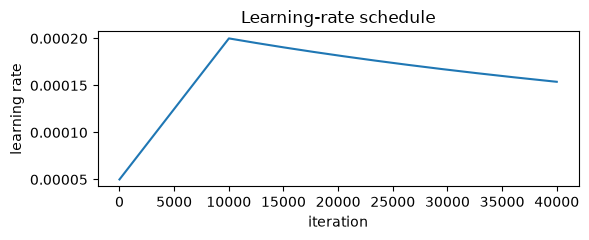

In [144]:
optimizer = torch.optim.Adam(
    [p for p in model.parameters() if p.requires_grad], lr=CONFIG["lr"])


def get_lr(it, cfg=CONFIG):
    if cfg.get("fixed_lr") is not None:
        return cfg["fixed_lr"]
    if it < cfg["warmup_iters"]:
        return cfg["lr"] * 0.1 * (1.0 + 3.0 * it / max(1, cfg["warmup_iters"]))
    return cfg["lr"] * 0.4 / (1.0 + cfg["lr_decay"] * (it - cfg["warmup_iters"]))


# 混合精度设置
use_amp = CONFIG["use_amp"] and DEVICE.type == "cuda"
amp_dtype = torch.bfloat16 if (use_amp and torch.cuda.is_bf16_supported()) else torch.float16
scaler = torch.amp.GradScaler("cuda", enabled=(use_amp and amp_dtype == torch.float16))
autocast = lambda: torch.autocast(device_type=DEVICE.type, dtype=amp_dtype, enabled=use_amp)
print("Mixed precision:", use_amp, amp_dtype if use_amp else "")

# 学习率曲线
its = np.arange(CONFIG["max_iters"])
plt.figure(figsize=(6, 2.5))
plt.plot(its, [get_lr(i) for i in its])
plt.xlabel("iteration"); plt.ylabel("learning rate"); plt.title("Learning-rate schedule")
plt.tight_layout(); plt.show()

In [145]:
CKPT_LATEST = OUTPUT_DIR / "ckpt_latest.pt"
CKPT_BEST = OUTPUT_DIR / "ckpt_best.pt"


def save_checkpoint(path, it, history, best_val):
    torch.save({"model": model.state_dict(), "optimizer": optimizer.state_dict(),
                "scaler": scaler.state_dict(), "iter": it, "history": history,
                "best_val": best_val, "config": {k: str(v) for k, v in CONFIG.items()}}, path)


@torch.no_grad()
def validate():
    model.eval()
    sums = {}
    bs = CONFIG["batch_size"]
    for i in range(0, len(val_content), bs):
        c = val_content[i:i + bs].to(DEVICE)
        s = val_style[i:i + bs].to(DEVICE)
        with autocast():
            losses, _ = compute_losses(model, vgg, c, s, CONFIG)
        for k, v in losses.items():
            sums[k] = sums.get(k, 0.0) + v.item() * len(c)
    model.train()
    return {k: v / len(val_content) for k, v in sums.items()}


@torch.no_grad()
def save_samples(it, n=6):
    model.eval()
    c, s = val_content[:n].to(DEVICE), val_style[:n].to(DEVICE)
    with autocast():
        out = model(c, s).float()
    model.train()
    out_std = out.std(dim=(1, 2, 3)).mean().item()
    flag = "  <-- WARNING: possible collapse (flat output)" if out_std < CONFIG["collapse_std"] else ""
    print(f"[iter {it}] sample output std = {out_std:.4f}{flag}")
    grid = torch.cat([c, s, out.clamp(0, 1)], dim=0)   # 三行：内容 / 风格 / 结果
    save_image(grid, OUTPUT_DIR / "samples" / f"iter_{it:06d}.png", nrow=n)

In [146]:
start_iter, history, best_val = 0, [], float("inf")
if CONFIG["resume"] and CKPT_LATEST.exists():
    ckpt = torch.load(CKPT_LATEST, map_location=DEVICE, weights_only=False)
    model.load_state_dict(ckpt["model"])
    optimizer.load_state_dict(ckpt["optimizer"])
    scaler.load_state_dict(ckpt["scaler"])
    start_iter, history, best_val = ckpt["iter"], ckpt["history"], ckpt["best_val"]
    print(f"Resumed from iteration {start_iter} (best val loss {best_val:.4f})")
else:
    print("Training from scratch")

Resumed from iteration 40000 (best val loss 45.7897)


In [147]:
model.train()
c_iter, s_iter = infinite(content_loader), infinite(style_loader)
running, t0 = {}, time.time()
pbar = tqdm(range(start_iter, CONFIG["max_iters"]), initial=start_iter, total=CONFIG["max_iters"], desc="Training")

for it in pbar:
    lr = get_lr(it)
    for g in optimizer.param_groups:
        g["lr"] = lr

    content = next(c_iter).to(DEVICE, non_blocking=True)
    style = next(s_iter).to(DEVICE, non_blocking=True)

    with autocast():
        losses, Ics = compute_losses(model, vgg, content, style, CONFIG)

    optimizer.zero_grad(set_to_none=True)
    scaler.scale(losses["total"]).backward()
    scaler.unscale_(optimizer)                       # 先还原梯度尺度，再裁剪
    if CONFIG["grad_clip"] is not None:
        grad_norm = torch.nn.utils.clip_grad_norm_(model.parameters(), CONFIG["grad_clip"])
    else:
        grad_norm = torch.nn.utils.clip_grad_norm_(model.parameters(), float("inf"))
    losses["grad_norm"] = grad_norm.detach()
    losses["out_std"] = Ics.detach().float().std(dim=(1, 2, 3)).mean()   # 输出图的像素标准差
    scaler.step(optimizer)
    scaler.update()

    for k, v in losses.items():
        running[k] = running.get(k, 0.0) + v.item()
    step = it + 1

    if step % CONFIG["log_every"] == 0:
        avg = {k: v / CONFIG["log_every"] for k, v in running.items()}
        it_per_s = CONFIG["log_every"] / (time.time() - t0)
        history.append({"iter": step, "split": "train", "lr": lr, **avg})
        if hasattr(pbar, "set_postfix"):
            pbar.set_postfix(total=f"{avg['total']:.3f}", c=f"{avg['content']:.3f}",
                             s=f"{avg['style']:.3f}", std=f"{avg['out_std']:.3f}",
                             it_s=f"{it_per_s:.2f}")
        # 刚初始化的模型输出本来就接近纯色，前 5 次记录不报警
        if step > 5 * CONFIG["log_every"] and avg["out_std"] < CONFIG["collapse_std"]:
            print(f"[iter {step}] WARNING: output std {avg['out_std']:.4f} < {CONFIG['collapse_std']} "
                  "- the model may be collapsing to a flat image. Check the samples; consider a lower lr.")
        running, t0 = {}, time.time()

    if step % CONFIG["val_every"] == 0:
        val = validate()
        history.append({"iter": step, "split": "val", "lr": lr, **val})
        if val["total"] < best_val:
            best_val = val["total"]
            save_checkpoint(CKPT_BEST, step, history, best_val)
        print(f"[iter {step}] val total {val['total']:.4f} | content {val['content']:.4f} | "
              f"style {val['style']:.4f} | best {best_val:.4f}")

    if step % CONFIG["sample_every"] == 0:
        save_samples(step)

    if step % CONFIG["save_every"] == 0 or step == CONFIG["max_iters"]:
        save_checkpoint(CKPT_LATEST, step, history, best_val)

pd.DataFrame(history).to_csv(OUTPUT_DIR / "history.csv", index=False)
print("Training finished. Best validation loss:", best_val)

Training: 100%|██████████| 40000/40000 [00:00<?, ?it/s]

Training finished. Best validation loss: 45.789724349975586


## 9. Training Curves / 训练曲线

Weighted contributions (λ × loss) are plotted so that the balance between the four terms is visible.

画出加权后（λ × loss）的各项损失，用于检查四项损失是否平衡。

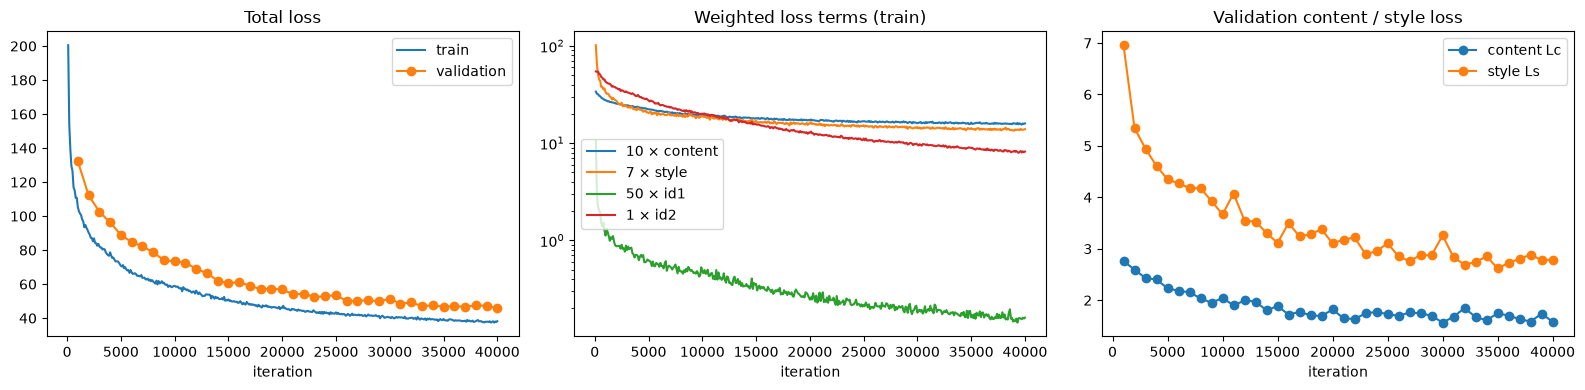

In [148]:
hist = pd.DataFrame(history)
if len(hist):
    tr, va = hist[hist.split == "train"], hist[hist.split == "val"]
    weights = {"content": CONFIG["lambda_c"], "style": CONFIG["lambda_s"],
               "id1": CONFIG["lambda_id1"], "id2": CONFIG["lambda_id2"]}
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    axes[0].plot(tr.iter, tr.total, label="train")
    if len(va):
        axes[0].plot(va.iter, va.total, "o-", label="validation")
    axes[0].set_title("Total loss"); axes[0].legend()
    for k, w in weights.items():
        axes[1].plot(tr.iter, w * tr[k], label=f"{w:g} × {k}")
    axes[1].set_title("Weighted loss terms (train)"); axes[1].legend(); axes[1].set_yscale("log")
    if len(va):
        axes[2].plot(va.iter, va.content, "o-", label="content Lc")
        axes[2].plot(va.iter, va["style"], "o-", label="style Ls")
    axes[2].set_title("Validation content / style loss"); axes[2].legend()
    for ax in axes:
        ax.set_xlabel("iteration")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "training_curves.png", dpi=150)
    plt.show()

## 10. Evaluation on the Test Set / 测试集评估

We load the checkpoint with the lowest validation loss and stylise **every test content image (400) with every style category (7)** = **2,800 results**. For each category and each content image, one style reference is randomly sampled (fixed seed) from that category's test paintings.

Results are saved in the agreed layout, one folder per style category:

```
test_results/
├── edvard_expressionism/
│   ├── 1_content.png      # resized content image
│   ├── 1_reference.png    # randomly sampled style reference
│   ├── 1_result.png       # stylised result
│   ├── 2_content.png
│   └── ...                (up to 400)
├── hokusai_ukiyoe/
└── ...                    (7 style folders)
```

The index `i` follows the sorted file names of `content_test/`, so `i` refers to the same content image in every folder. The full mapping (index → content file, reference file) and the per-pair metrics are saved in `test_metrics_per_pair.csv`.

载入验证损失最低的模型，把 400 张测试内容图分别用 7 个风格类别各生成一遍，共 2800 张。每个类别、每张内容图从该类别的测试风格图中随机抽一张作为参考图（固定随机种子）。结果按上面的目录结构保存，序号 `i` 按 `content_test/` 文件名排序，所以同一个序号在每个文件夹里都是同一张内容图。


In [149]:
ckpt_path = CKPT_BEST if CKPT_BEST.exists() else CKPT_LATEST
ckpt = torch.load(ckpt_path, map_location=DEVICE, weights_only=False)
model.load_state_dict(ckpt["model"])
model.eval()
print(f"Loaded {ckpt_path.name} (iteration {ckpt['iter']})")


@torch.no_grad()
def stylize(content, style):
    # content / style: B,3,H,W in [0,1]，尺寸需为 8 的倍数
    with autocast():
        return model(content.to(DEVICE), style.to(DEVICE)).float().clamp(0, 1)


def load_image(path, size=None):
    img = Image.open(path).convert("RGB")
    if size is not None:
        img = transforms.CenterCrop(size)(transforms.Resize(size)(img))
    w, h = img.size                        # 裁成 8 的倍数
    img = img.crop((0, 0, w - w % 8, h - h % 8))
    return transforms.ToTensor()(img).unsqueeze(0)


# 测试对：每个风格类别 × 全部测试内容图；每张内容图从该类别中随机抽一张风格参考图
test_contents = sorted(c_test)                 # 按文件名排序，序号 i 从 1 开始
if CONFIG["eval_num_content"] is not None:
    test_contents = test_contents[:CONFIG["eval_num_content"]]

eval_rng = random.Random(CONFIG["seed"])
test_pairs = []                                # (风格类别, 序号, 内容图路径, 参考图路径)
for cls in STYLE_CLASSES:
    pool = sorted(p for p in s_test if p.parent.name == cls)
    for idx, cp in enumerate(test_contents, start=1):
        test_pairs.append((cls, idx, cp, eval_rng.choice(pool)))

print(len(STYLE_CLASSES), "style folders ×", len(test_contents), "content images =", len(test_pairs), "results")


Loaded ckpt_best.pt (iteration 40000)
7 style folders × 400 content images = 2800 results


### 10.1 Qualitative Results / 定性结果

Each row is a content image; each column is one style category.

每一行是一张内容图，每一列是一个风格类别。

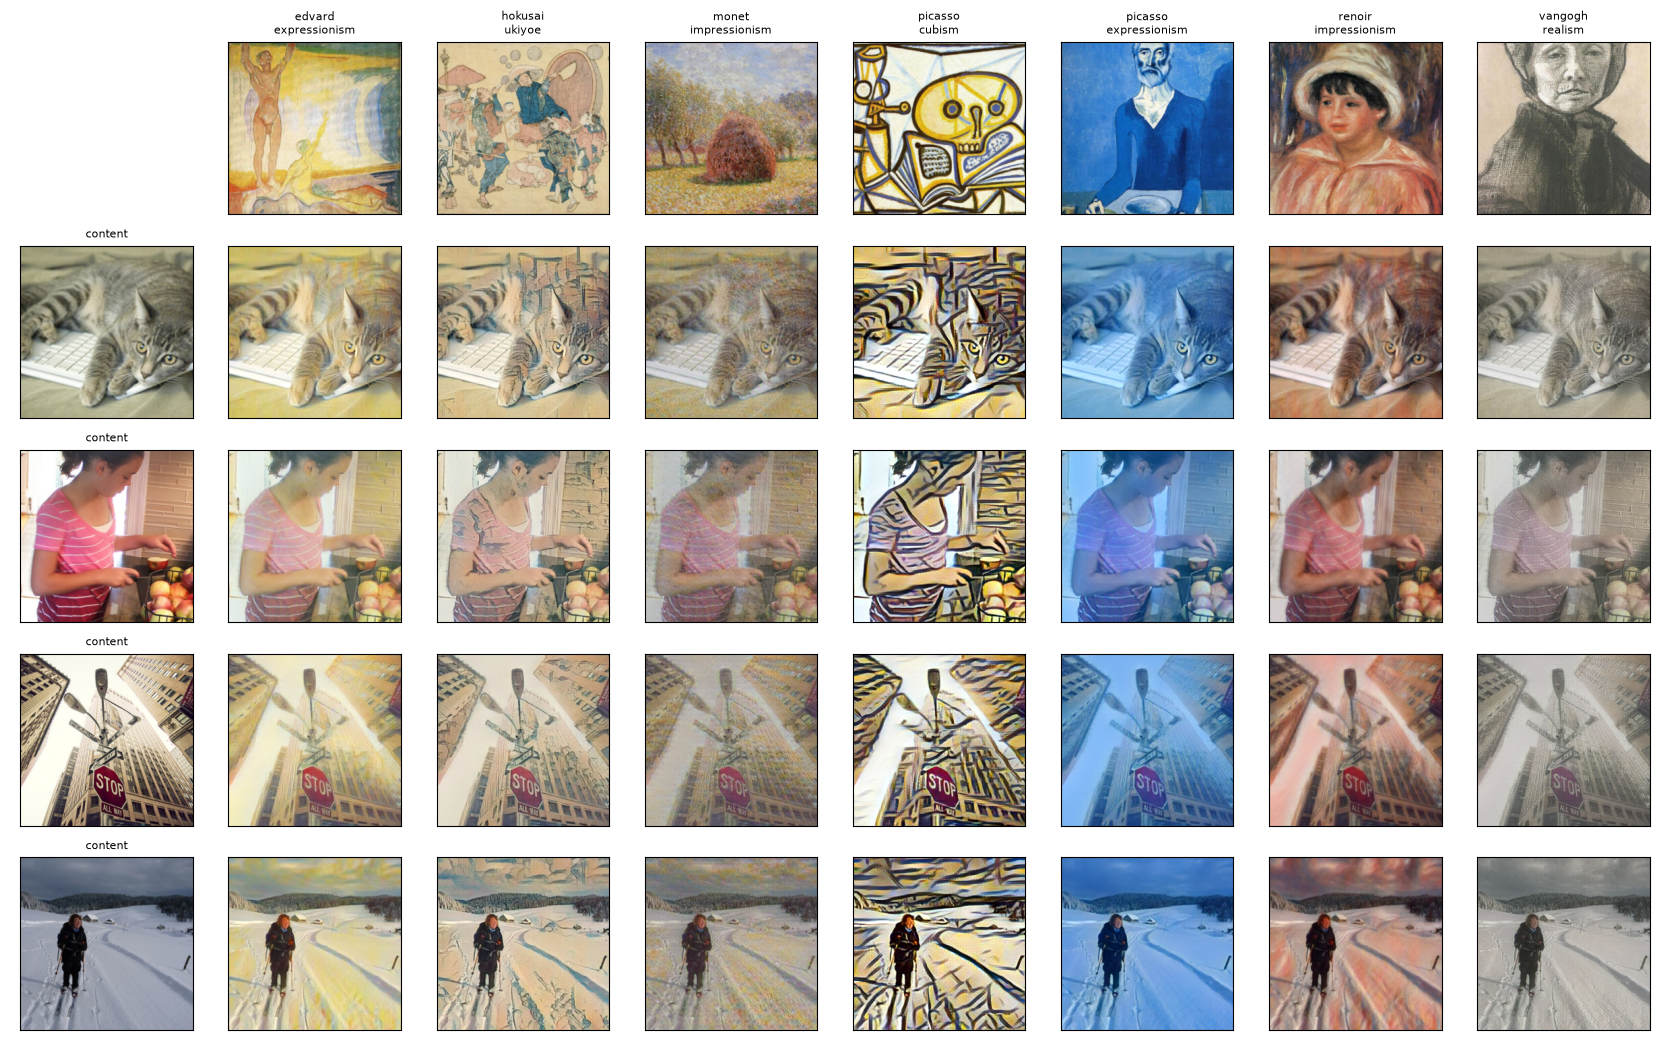

In [150]:
n_show = min(4, len(test_contents))
one_per_class = [next(r for c, i, _, r in test_pairs if c == cls and i == 1) for cls in STYLE_CLASSES]
cols = len(one_per_class) + 1
fig, axes = plt.subplots(n_show + 1, cols, figsize=(2.1 * cols, 2.1 * (n_show + 1)))
axes[0, 0].axis("off")
for j, sp in enumerate(one_per_class, start=1):
    axes[0, j].imshow(load_image(sp, IMG)[0].permute(1, 2, 0))
    axes[0, j].set_title(sp.parent.name.replace("_", "\n"), fontsize=8)
for i, cp in enumerate(test_contents[:n_show], start=1):
    c = load_image(cp, IMG)
    axes[i, 0].imshow(c[0].permute(1, 2, 0))
    axes[i, 0].set_title("content", fontsize=8)
    for j, sp in enumerate(one_per_class, start=1):
        axes[i, j].imshow(stylize(c, load_image(sp, IMG))[0].cpu().permute(1, 2, 0))
for ax in axes.ravel():
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "qualitative_grid.png", dpi=150)
plt.show()

### 10.2 Quantitative Results / 定量结果

| Metric | Meaning | Better |
|---|---|---|
| Content loss Lc | Eq. 9 between output and content (as in the paper's Table 2) | lower |
| Style loss Ls | Eq. 10 between output and style (as in the paper's Table 2) | lower |
| SSIM | Structural similarity between output and content (grayscale), independent of VGG | higher |

Lc and Ls are the same quantities the model is trained on, so they favour methods trained with them; SSIM (and ArtFID, see §11) give a VGG-independent view. All results are saved to `outputs/.../test_results/` for comparison with other groups.

Lc 和 Ls 就是训练时优化的指标，会偏向用它们训练的方法；SSIM 与 VGG 无关，可作为补充。所有结果图都保存下来，方便与其他实验组比较。

In [151]:
def ssim_gray(x, y, window_size=11, sigma=1.5):
    # 灰度 SSIM，x / y: B,3,H,W in [0,1]
    w = torch.tensor([0.299, 0.587, 0.114], device=x.device).view(1, 3, 1, 1)
    x, y = (x * w).sum(1, keepdim=True), (y * w).sum(1, keepdim=True)
    coords = torch.arange(window_size, dtype=torch.float32, device=x.device) - window_size // 2
    g = torch.exp(-coords ** 2 / (2 * sigma ** 2)); g = g / g.sum()
    win = (g[:, None] * g[None, :]).view(1, 1, window_size, window_size)
    pad = window_size // 2
    mu_x, mu_y = F.conv2d(x, win, padding=pad), F.conv2d(y, win, padding=pad)
    sxx = F.conv2d(x * x, win, padding=pad) - mu_x ** 2
    syy = F.conv2d(y * y, win, padding=pad) - mu_y ** 2
    sxy = F.conv2d(x * y, win, padding=pad) - mu_x * mu_y
    c1, c2 = 0.01 ** 2, 0.03 ** 2
    ssim_map = ((2 * mu_x * mu_y + c1) * (2 * sxy + c2)) / ((mu_x ** 2 + mu_y ** 2 + c1) * (sxx + syy + c2))
    return ssim_map.mean(dim=(1, 2, 3))


TEST_DIR = OUTPUT_DIR / "test_results"

records = []
with torch.no_grad():
    for cls, idx, cp, sp in tqdm(test_pairs, desc="Testing"):
        out_dir = TEST_DIR / cls
        out_dir.mkdir(parents=True, exist_ok=True)
        c = load_image(cp, IMG).to(DEVICE)          # 缩放后的内容图
        s = load_image(sp, IMG).to(DEVICE)          # 随机抽样的风格参考图
        out = stylize(c, s)                         # 风格化结果
        save_image(c, out_dir / f"{idx}_content.png")
        save_image(s, out_dir / f"{idx}_reference.png")
        save_image(out, out_dir / f"{idx}_result.png")

        f_c, f_s, f_o = vgg(c), vgg(s), vgg(out)
        records.append({
            "category": cls, "index": idx, "content": cp.name, "reference": sp.name,
            "content_loss": content_loss(f_o, f_c).item(),
            "style_loss": style_loss(f_o, f_s).item(),
            "ssim": ssim_gray(out, c).item(),
        })

results = pd.DataFrame(records)
results.to_csv(OUTPUT_DIR / "test_metrics_per_pair.csv", index=False)   # 同时记录了 序号 → 内容图 / 参考图 的对应关系

summary = results[["content_loss", "style_loss", "ssim"]].agg(["mean", "std"]).T.round(4)
summary.columns = ["mean", "std"]
display(summary)


Testing: 100%|██████████| 2800/2800 [03:54<00:00, 11.95it/s]


,mean,std
content_loss,1.4762,0.4169
style_loss,2.7780,1.5226
ssim,0.6588,0.1325


,content_loss,style_loss,ssim
category,,,
edvard_expressionism,1.3647,2.5890,0.7001
hokusai_ukiyoe,1.7041,4.0105,0.5666
monet_impressionism,1.4236,2.2575,0.6654
picasso_cubism,1.6665,3.6382,0.6369
picasso_expressionism,1.4606,2.8221,0.6469
renoir_impressionism,1.4138,2.3517,0.6934
vangogh_realism,1.3000,1.7767,0.7020


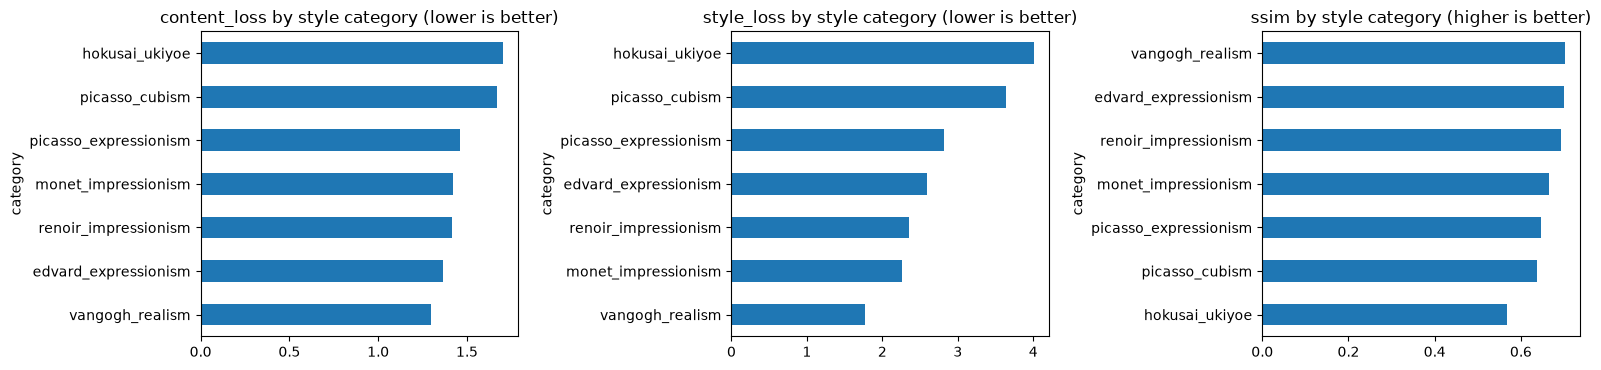

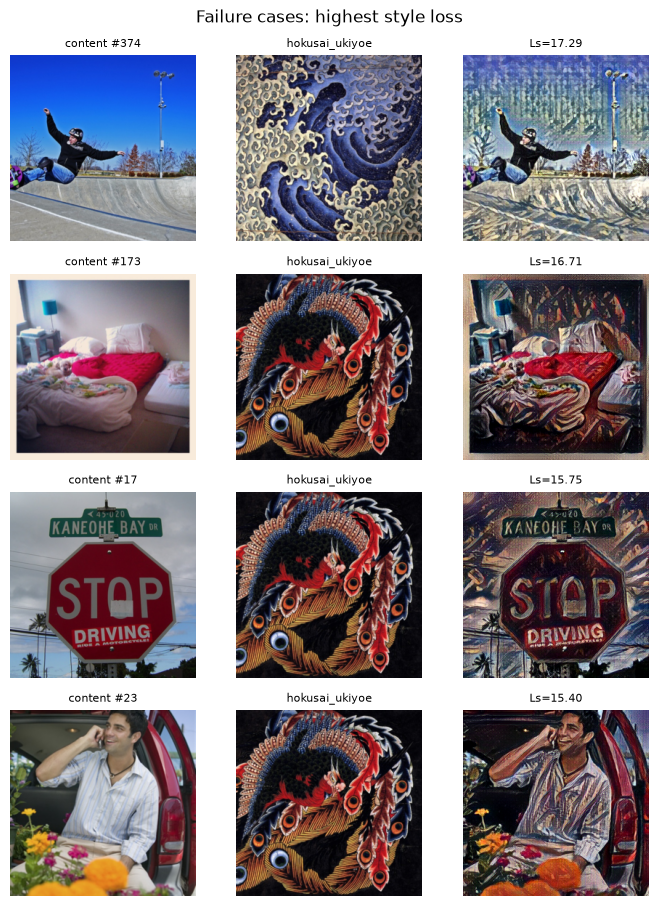

In [152]:
per_class = results.groupby("category")[["content_loss", "style_loss", "ssim"]].mean().round(4)
display(per_class)

fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
for ax, col, better in zip(axes, ["content_loss", "style_loss", "ssim"], ["lower", "lower", "higher"]):
    per_class[col].sort_values().plot(kind="barh", ax=ax)
    ax.set_title(f"{col} by style category ({better} is better)")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "metrics_by_category.png", dpi=150)
plt.show()

# 错误分析：风格损失最高（风格迁移最差）的几对
worst = results.sort_values("style_loss", ascending=False).head(4)
fig, axes = plt.subplots(len(worst), 3, figsize=(7, 2.3 * len(worst)))
axes = np.atleast_2d(axes)
for row, (_, r) in zip(axes, worst.iterrows()):
    folder, i = TEST_DIR / r["category"], r["index"]
    for ax, img_path, title in zip(row, [folder / f"{i}_content.png",
                                         folder / f"{i}_reference.png",
                                         folder / f"{i}_result.png"],
                                   [f"content #{i}", r["category"], f"Ls={r['style_loss']:.2f}"]):
        ax.imshow(Image.open(img_path)); ax.set_title(title, fontsize=8); ax.axis("off")
plt.suptitle("Failure cases: highest style loss")
plt.tight_layout(); plt.show()

### 10.3 Inference Time / 推理速度

Average forward time per image at 256×256 and 512×512 (paper Table 1 reports 0.116 s and 0.661 s on a Tesla P100).

在 256×256 和 512×512 下测量单张图的平均推理时间（论文在 P100 上为 0.116 s 和 0.661 s）。

In [153]:
@torch.no_grad()
def time_inference(size, runs=20, warmup=5):
    c = torch.rand(1, 3, size, size, device=DEVICE)
    s = torch.rand(1, 3, size, size, device=DEVICE)
    for _ in range(warmup):
        stylize(c, s)
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    t = time.perf_counter()
    for _ in range(runs):
        stylize(c, s)
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    return (time.perf_counter() - t) / runs


runs = 3 if CONFIG["quick_test"] else 20
timing = pd.DataFrame({"seconds / image": [time_inference(256, runs), time_inference(512, runs)]},
                      index=["256×256", "512×512"]).round(4)
display(timing)

,seconds / image
256×256,0.0107
512×512,0.0549


## 11. Saved Outputs and Next Steps / 输出文件与后续工作

| File | Content |
|---|---|
| `config.json`, `history.csv` | hyper-parameters and loss history |
| `ckpt_best.pt`, `ckpt_latest.pt` | model checkpoints |
| `samples/iter_*.png` | validation samples during training (content / style / output rows) |
| `test_results/<style>/{i}_content.png`, `{i}_reference.png`, `{i}_result.png` | 2,800 test results (7 style folders × 400), for comparison with other groups |
| `test_metrics_per_pair.csv` | index → content / reference file mapping, and per-pair content loss, style loss, SSIM |
| `training_curves.png`, `qualitative_grid.png`, `metrics_by_category.png` | figures for the report and slides |

**ArtFID** (Wright & Ommer, 2022) can be computed from the saved folders with the `art-fid` package (`pip install art_fid`); see its README for the expected folder layout.

**Comparison with our own model / 与主模型对比**

Our own model should use the same data splits, training budget (iterations, batch size, image size) and test pairs, and save its results in the same `test_results/<style>/{i}_*.png` layout, ideally reusing the content/reference pairs listed in `test_metrics_per_pair.csv`, so both methods are evaluated on identical inputs.

主模型应使用相同的数据划分、训练预算和测试对，并按相同的 `test_results/<风格>/{i}_*.png` 目录结构保存结果（最好直接使用 `test_metrics_per_pair.csv` 里的内容图/参考图配对），保证两者在完全相同的输入上比较。


In [154]:
print("Outputs saved in:", OUTPUT_DIR)
for p in sorted(OUTPUT_DIR.rglob("*")):
    if p.is_file() and "test_results" not in p.parts and "samples" not in p.parts:
        print("  ", p.relative_to(OUTPUT_DIR))

Outputs saved in: d:\9444\Project\outputs\stytr2_cape
   ckpt_best.pt
   ckpt_latest.pt
   config.json
   eval\content\COCO_test2014_000000012380.png
   eval\content\COCO_test2014_000000014227.png
   eval\content\COCO_test2014_000000015381.png
   eval\content\COCO_test2014_000000039164.png
   eval\content\COCO_test2014_000000044513.png
   eval\content\COCO_test2014_000000048230.png
   eval\content\COCO_test2014_000000050830.png
   eval\content\COCO_test2014_000000059045.png
   eval\content\COCO_test2014_000000102089.png
   eval\content\COCO_test2014_000000106798.png
   eval\content\COCO_test2014_000000112308.png
   eval\content\COCO_test2014_000000116971.png
   eval\content\COCO_test2014_000000129425.png
   eval\content\COCO_test2014_000000180151.png
   eval\content\COCO_test2014_000000231297.png
   eval\content\COCO_test2014_000000256321.png
   eval\content\COCO_test2014_000000274243.png
   eval\content\COCO_test2014_000000288053.png
   eval\content\COCO_test2014_000000317486.png
   e

In [155]:
print(torch.cuda.max_memory_allocated() / 1024**3)

11.832001209259033
